In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
%matplotlib inline
from sklearn.datasets import load_diabetes
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn import tree
import warnings
warnings.filterwarnings('ignore')

In [2]:
dataset = load_diabetes()

In [3]:
print(dataset.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [4]:
df = pd.DataFrame(dataset.data, columns=dataset.feature_names)
df['target'] = dataset.target

In [5]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [6]:
X = df.drop('target', axis=1)
y = df['target']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [8]:
X_train.corr()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,1.000000,0.136522,0.181976,0.308406,0.261534,0.200301,-0.023100,0.165340,0.270981,0.262201
sex,0.136522,1.000000,0.044746,0.165128,0.033717,0.128023,-0.344052,0.320619,0.121299,0.159936
bmi,0.181976,0.044746,1.000000,0.384534,0.246802,0.255519,-0.372335,0.431946,0.448657,0.394699
bp,0.308406,0.165128,0.384534,1.000000,0.242052,0.164355,-0.113747,0.209316,0.362476,0.376421
s1,0.261534,0.033717,0.246802,0.242052,1.000000,0.891476,0.044128,0.556987,0.528922,0.323666
s2,0.200301,0.128023,0.255519,0.164355,0.891476,1.000000,-0.190767,0.653120,0.307541,0.298647
s3,-0.023100,-0.344052,-0.372335,-0.113747,0.044128,-0.190767,1.000000,-0.732862,-0.388778,-0.304091
s4,0.165340,0.320619,0.431946,0.209316,0.556987,0.653120,-0.732862,1.000000,0.629707,0.441489
s5,0.270981,0.121299,0.448657,0.362476,0.528922,0.307541,-0.388778,0.629707,1.000000,0.464878
s6,0.262201,0.159936,0.394699,0.376421,0.323666,0.298647,-0.304091,0.441489,0.464878,1.000000


<Axes: >

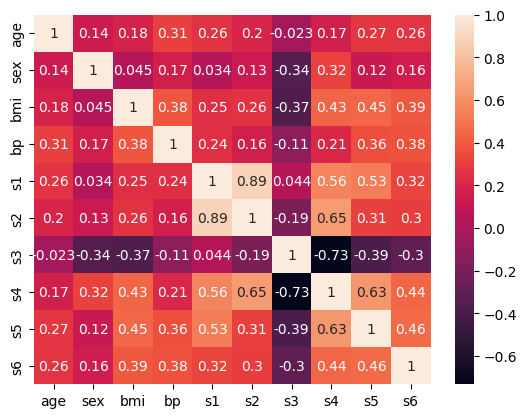

In [9]:
sns.heatmap(X_train.corr(), annot=True)

In [10]:
model = DecisionTreeRegressor()
model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [11]:
pred = model.predict(X_test)

In [ ]:
print("Mean Squared Error:", mean_squared_error(y_test, pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, pred))
print("R2 Score:", r2_score(y_test, pred))

Mean Squared Error: 5941.458646616541
R2 Score: -0.10061502765097474


In [13]:
param_grid = {
    "criterion": ["squared_error", "friedman_mse", "absolute_error", "poisson"],
    "splitter": ["best", "random"],
    "max_depth": [1,2,3,4,5,10,15,20,25],
    'max_features': ['auto', 'sqrt', 'log2']
}

In [14]:
model = GridSearchCV(DecisionTreeRegressor(),param_grid=param_grid, cv=5,scoring = 'neg_mean_squared_error')
model.fit(X_train, y_train)

,estimator,DecisionTreeRegressor()
,param_grid,"{'criterion': ['squared_error', 'friedman_mse', ...], 'max_depth': [1, 2, ...], 'max_features': ['auto', 'sqrt', ...], 'splitter': ['best', 'random']}"
,scoring,'neg_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [15]:
model.best_params_

{'criterion': 'squared_error',
 'max_depth': 5,
 'max_features': 'sqrt',
 'splitter': 'random'}

In [16]:
model.best_score_

np.float64(-4056.4003484216432)

In [ ]:
pred = model.predict(X_test)
print("Mean Squared Error:", mean_squared_error(y_test, pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, pred))
print("R2 Score:", r2_score(y_test, pred))

Mean Squared Error: 3865.4770665664473
R2 Score: 0.28394651860011233


In [20]:
model = DecisionTreeRegressor(criterion= 'squared_error',max_depth=5,max_features='sqrt',splitter='random')
model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'random'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


[Text(0.5714285714285714, 0.9166666666666666, 'x[2] <= 0.089\nsquared_error = 6148.282\nsamples = 309\nvalue = 153.903'),
 Text(0.32653061224489793, 0.75, 'x[6] <= 0.023\nsquared_error = 5558.372\nsamples = 293\nvalue = 147.621'),
 Text(0.44897959183673464, 0.8333333333333333, 'True  '),
 Text(0.16326530612244897, 0.5833333333333334, 'x[7] <= 0.008\nsquared_error = 5542.448\nsamples = 214\nvalue = 161.248'),
 Text(0.08163265306122448, 0.4166666666666667, 'x[2] <= 0.006\nsquared_error = 5121.997\nsamples = 117\nvalue = 140.282'),
 Text(0.04081632653061224, 0.25, 'x[4] <= -0.008\nsquared_error = 3179.098\nsamples = 77\nvalue = 113.688'),
 Text(0.02040816326530612, 0.08333333333333333, 'squared_error = 3232.016\nsamples = 61\nvalue = 109.016'),
 Text(0.061224489795918366, 0.08333333333333333, 'squared_error = 2576.875\nsamples = 16\nvalue = 131.5'),
 Text(0.12244897959183673, 0.25, 'x[3] <= -0.032\nsquared_error = 4879.949\nsamples = 40\nvalue = 191.475'),
 Text(0.10204081632653061, 0.083

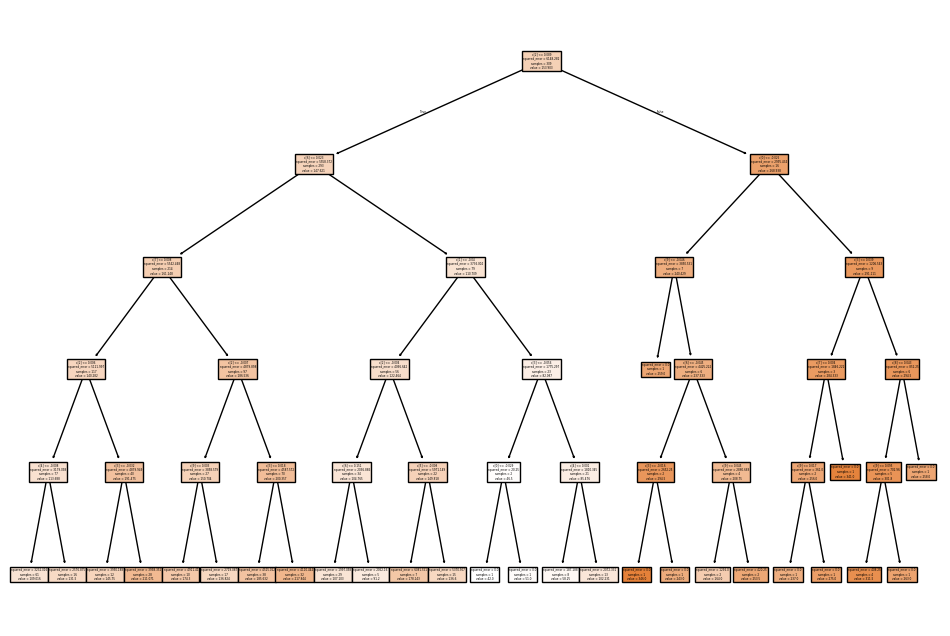

In [21]:
plt.figure(figsize = (12, 8))
tree.plot_tree(model, filled=True)